# 07 · Finetuning: quando ajustar, quanto custa e como LoRA e quantização funcionam

> **Capítulo 7 do livro:** *Finetuning*.
> Prompt (cap. 5) e RAG (cap. 6) mudam o que o modelo **recebe**. Finetuning muda o que o modelo **é**: os pesos.

**Objetivo:** decidir quando ajustar vale a pena, fazer a **conta de memória** de verdade, e implementar do zero, em numpy, uma rede pequena com **ajuste completo**, **LoRA** e **quantização**, com os gradientes escritos à mão.

## Antes de começar

- **Você precisa saber:** os notebooks 02 (parâmetros, memória, quantização em conceito) e 03 (embeddings por co-ocorrência).
- **Sobre o experimento:** a rede é pequena (alguns milhares de parâmetros) e o problema é de classificação, não de geração de texto. Isso é de propósito: o **mecanismo** do LoRA é o mesmo em um modelo de 70 bilhões de parâmetros (uma matriz `W` ganha um desvio de posto baixo), mas **os números aqui não se transferem** para um modelo grande. Transfere-se o raciocínio e a conta de memória, que usa tamanhos reais.
- **Tempo:** 70 minutos.

## Mapa do notebook

1. Quando ajustar, e quando não
2. A conta de memória: ajuste completo, LoRA, QLoRA
3. A rede pequena e o pré-treino
4. Quatro formas de adaptar a rede a uma tarefa nova
5. LoRA por dentro
6. O preço do ajuste completo: esquecimento
7. Quantos exemplos fazem falta
8. Quantização, e QLoRA em miniatura

In [1]:
import sys, pathlib, random
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
%matplotlib inline
import matplotlib.pyplot as plt

## 1. Quando ajustar, e quando não

A pergunta certa não é "dá para ajustar?", e sim "**o que está faltando?**".

| O que falta | Primeira tentativa | Por quê |
|---|---|---|
| o modelo não sabe um **fato** (manual, preço, estado do coletor) | **RAG** ou ferramenta | fato muda, e RAG é atualizável e rastreável |
| o modelo não segue o **formato** ou a instrução | **prompt** com exemplos | barato e reversível |
| o modelo erra um **comportamento estreito e repetido** (rotular paradas no jargão da sua planta, extrair campos de um tipo de nota) | **finetuning** | o comportamento vira parte do modelo |
| é preciso **menor custo ou latência** num modelo menor | finetuning de um modelo pequeno com os dados de um grande | o pequeno aprende só a tarefa |
| o dado **não pode sair** da rede OT | modelo local, possivelmente ajustado | privacidade |

Regra prática: **conhecimento via RAG, comportamento via finetuning**. Ajustar para "ensinar o manual" costuma dar um modelo que decora trechos e inventa o resto, e que fica velho quando o manual muda.

Antes de ajustar, confira a lista:

1. Já tentou **prompt com exemplos** e **RAG**, e mediu num conjunto de avaliação (cap. 4)?
2. Tem **dados**: centenas a milhares de exemplos **de boa qualidade** (cap. 8)?
3. Sabe medir o ganho e o **esquecimento** (o que o modelo perdeu)?
4. Aceita manter um **artefato novo**: versionar, reajustar a cada troca do modelo base?

Se a resposta a qualquer uma é "não", o ajuste ainda não é o próximo passo.

## 2. A conta de memória: ajuste completo, LoRA, QLoRA

Rodar um modelo exige guardar os **pesos**. **Treinar** exige mais: os **gradientes** (um por parâmetro) e os **estados do otimizador** (o Adam guarda dois números por parâmetro, mais uma cópia dos pesos em precisão alta). A regra comum para ajuste completo com precisão mista: **cerca de 16 bytes por parâmetro**, contra 2 bytes só para rodar em FP16. Fora disso ainda entram as **ativações**, que dependem do tamanho do lote e do contexto.

O **LoRA** congela os pesos e treina só pequenas matrizes acrescentadas. O **QLoRA** vai além: guarda os pesos congelados em 4 bits.

modelo   rodar FP16  ajuste completo     LoRA    QLoRA   parâmetros treináveis no LoRA (r=16)
1,5 B           3 GB             24 GB      3 GB      1 GB   6 milhões (0.37% do modelo)
7 B            14 GB            112 GB     14 GB      4 GB   17 milhões (0.24% do modelo)
13 B           26 GB            208 GB     26 GB      7 GB   26 milhões (0.20% do modelo)
70 B          140 GB           1120 GB    141 GB     36 GB   84 milhões (0.12% do modelo)


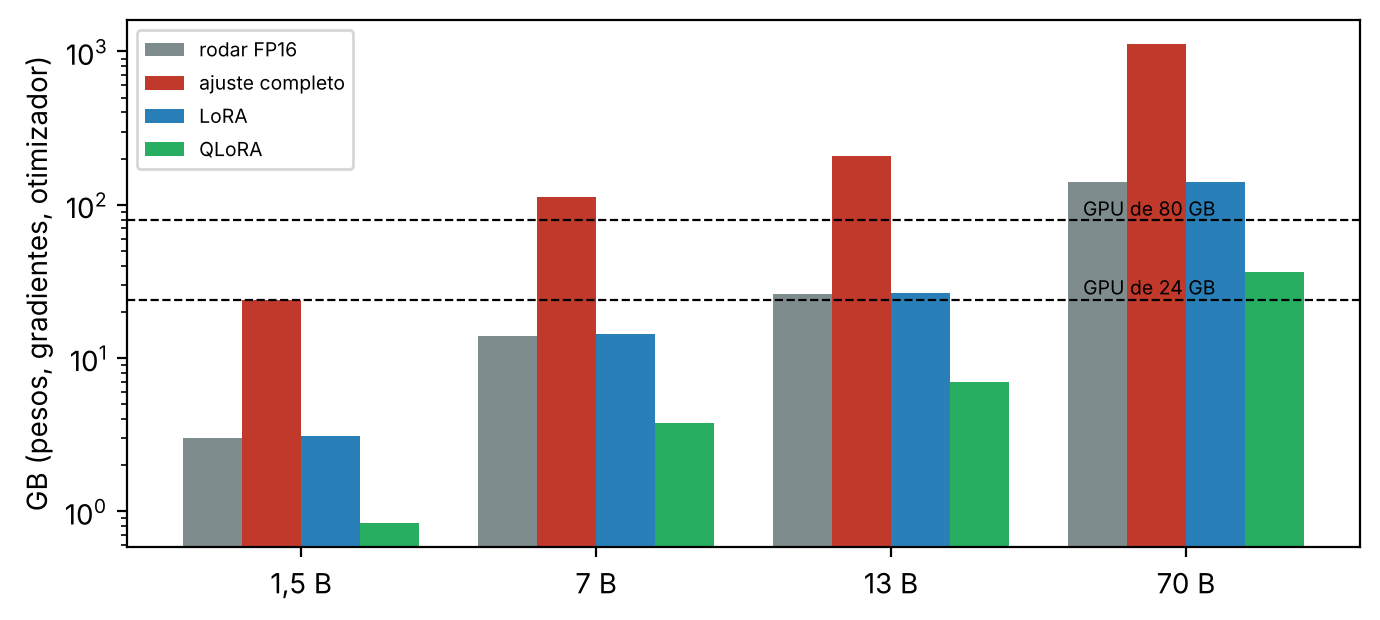

In [2]:
from aiind.finetune import *
from aiind.foundation import transformer_params
import numpy as np
# modelos de tamanhos reais: (camadas, largura)
modelos = {"1,5 B": (1.5e9, 28, 1536), "7 B": (7e9, 32, 4096), "13 B": (13e9, 40, 5120), "70 B": (70e9, 80, 8192)}
rank = 16
print(f"{'modelo':7s} {'rodar FP16':>11s} {'ajuste completo':>16s} {'LoRA':>8s} {'QLoRA':>8s}   parâmetros treináveis no LoRA (r={rank})")
mem = {}
for nome, (P, L, d) in modelos.items():
    t = lora_params(L, d, rank)
    mem[nome] = [P * 2 / 1e9, train_memory_gb(P, "full"), train_memory_gb(P, "lora", t), train_memory_gb(P, "qlora", t)]
    print(f"{nome:7s} {mem[nome][0]:9.0f} GB {mem[nome][1]:14.0f} GB {mem[nome][2]:6.0f} GB {mem[nome][3]:6.0f} GB   {t/1e6:.0f} milhões ({t/P:.2%} do modelo)")
fig, ax = plt.subplots(figsize=(7, 3.2)); x = np.arange(4); w = 0.2
for i, (rot, cor) in enumerate(zip(["rodar FP16", "ajuste completo", "LoRA", "QLoRA"], ["#7f8c8d", "#c0392b", "#2980b9", "#27ae60"])):
    ax.bar(x + i * w, [mem[n][i] for n in modelos], w, label=rot, color=cor)
ax.axhline(24, ls="--", c="k", lw=.8); ax.text(3.4, 26, "GPU de 24 GB", fontsize=7, ha="right"); ax.axhline(80, ls="--", c="k", lw=.8); ax.text(3.4, 85, "GPU de 80 GB", fontsize=7, ha="right")
ax.set_yscale("log"); ax.set_xticks(x + 1.5 * w, list(modelos)); ax.set_ylabel("GB (pesos, gradientes, otimizador)"); ax.legend(fontsize=7); plt.tight_layout()

### Pare e preveja

Qual dessas combinações cabe numa GPU de 24 GB: ajuste completo de 7 B, LoRA de 7 B, QLoRA de 7 B?

Pela tabela: o ajuste completo de um modelo de 7 B pede **mais de 100 GB** (precisa de várias GPUs); o LoRA de 7 B pede uns **14 GB** e **cabe**; o QLoRA, uns **4 GB**. Para 70 B, o completo passa de 1 TB, e o QLoRA fica em torno de 36 GB. É por isso que quase todo ajuste fora de grandes laboratórios é LoRA ou QLoRA.

Sobre a conta: os **LoRA de r=16 treinam menos de 1 % dos parâmetros**, e o que mais pesa na memória é o modelo **congelado**, não o adaptador. Ativações e contexto longo acrescentam gigabytes, então trate a tabela como um piso.

## 3. A rede pequena e o pré-treino

Para ver o mecanismo com as próprias mãos, uma rede minúscula em numpy lê uma anotação como **saco de palavras**: a média dos vetores das palavras, uma camada oculta `tanh(x W + b)`, e uma "cabeça" que dá a classe.

- **Os vetores das palavras (`E`)** vêm de um **pré-treino** sem rótulos, por co-ocorrência (notebook 03): sinônimos como "vazando" e "pingando" ficam juntos.
- **A matriz `W`** é pré-treinada numa **primeira tarefa**: dizer qual **máquina** aparece na anotação.
- **A tarefa nova** é dizer a **família da falha** (vazamento, travamento, ruído, calor, leitura). Ela tem pouquíssimos exemplos de treino, e **eles mostram só 2 dos 4 sinônimos** de cada família. O teste usa todos. Ou seja: a rede precisa **generalizar para palavras que nunca viu rotuladas**, e o que ajuda nisso é o conhecimento dos vetores.

Os gradientes estão escritos à mão em `aiind/finetune.py` e conferidos contra derivadas numéricas nos testes.

In [3]:
import copy
from aiind.evaluation import fault_notes, Embedder
big = [t for t, _, _ in fault_notes(3000, 1)]
voc = vocab_of(big + [t for t, _, _ in fault_notes(3000, 2)]); V = len(voc)
emb = Embedder(32).fit(big)
E0 = np.zeros((V, 32))
for w, i in voc.items():
    if w in emb.idx:
        E0[i] = emb.W[emb.idx[w]]
E0 /= np.linalg.norm(E0, axis=1).mean()

# pré-treino da matriz W na tarefa A (qual máquina?)
tA, yA, _ = task_data(1500, 11); XA = bow(tA, voc)
teA, yteA, _ = task_data(500, 12); XteA = bow(teA, voc)
base = Net(V, seed=0); base.p["E"] = E0.copy(); base.add_head("A", 6)
fit(base, XA, yA, "A", {"W", "b", "Wo", "bo"}, epochs=300, lr=0.02)
print(f"modelo base: {V} palavras, {n_params(base, ['E', 'W', 'b']):,} parâmetros na base")
print(f"tarefa A (máquina), em texto novo: {base.accuracy(XteA, yteA, 'A'):.0%}")
teB, _, yteB = task_data(600, 999); XteB = bow(teB, voc)
print("\ntarefa B, exemplo de treino:", task_data(3, 100, symptoms_seen=2)[0][:2], "... só vê 2 dos 4 sinônimos de cada família")
print("tarefa B, exemplos do teste: ", teB[:2])

modelo base: 55 palavras, 3,872 parâmetros na base
tarefa A (máquina), em texto novo: 100%

tarefa B, exemplo de treino: ['rotuladora parada rolo de cola com ruído', 'parada na prensa cilindro hidráulico aquecendo'] ... só vê 2 dos 4 sinônimos de cada família
tarefa B, exemplos do teste:  ['cilindro hidráulico escorrendo na prensa', 'parada na esteira rolamento barulho']


## 4. Quatro formas de adaptar a rede a uma tarefa nova

Com 40 exemplos rotulados da tarefa nova:

1. **Do zero:** rede nova, sem pré-treino. É a linha de base: quanto o conhecimento prévio ajuda?
2. **Só a cabeça:** congela tudo e treina só a camada de saída (sondagem linear).
3. **Ajuste completo:** treina **tudo**: vetores `E`, matriz `W`, cabeça.
4. **LoRA (posto 4):** congela `E` e `W`, treina um **desvio de posto baixo** em `W` e a cabeça.

### Pare e preveja

Qual método generaliza melhor para os sinônimos que não apareceram no treino? O ajuste completo, por mexer em mais coisas, deve ganhar?

In [4]:
def rodar_B(n, metodo, rank=4, lr=0.02, seed=0, epocas=300, rede=None, treino_seen=2):
    tB, _, yB = task_data(n, 100 + seed, symptoms_seen=treino_seen); XB = bow(tB, voc)
    net = copy.deepcopy(rede or base) if metodo != "do zero" else Net(V, seed=seed)
    net.add_head("B", 5)
    treino = {"do zero": {"E", "W", "b", "Wo", "bo"}, "só a cabeça": {"Wo", "bo"}, "completo": {"E", "W", "b", "Wo", "bo"}, "LoRA": {"U", "Vt", "Wo", "bo"}}[metodo]
    if metodo == "LoRA":
        net.add_lora(rank)
    fit(net, XB, yB, "B", treino, epochs=epocas, lr=lr)
    return net.accuracy(XteB, yteB, "B"), (net.accuracy(XteA, yteA, "A") if "A" in net.heads else float("nan")), net, treino

metodos = ["do zero", "só a cabeça", "completo", "LoRA"]
res = {m: [rodar_B(40, m, seed=s)[0] for s in range(5)] for m in metodos}
_, _, net_ex, _ = rodar_B(40, "completo")
print(f"{'método':14s} {'acerto em B (5 sementes)':>26s} {'parâmetros treinados':>22s}")
for m in metodos:
    _, _, net, tr = rodar_B(40, m)
    print(f"{m:14s} {np.mean(res[m]):10.1%}  ±{np.std(res[m]):.1%} {'':8s} {n_params(net, tr):22,d}")

método           acerto em B (5 sementes)   parâmetros treinados
do zero             81.5%  ±2.4%                           4,197
só a cabeça         96.5%  ±3.2%                             390
completo            88.0%  ±3.4%                           4,262
LoRA                97.1%  ±3.2%                             774


O resultado contraria a intuição de que mexer em mais coisas ajuda mais:

- **Do zero** é o pior: sem o conhecimento prévio, a rede não tem como saber que "pingando" se parece com "vazando".
- **LoRA** e **só a cabeça** chegam a ~97 %, treinando **de 5 a 10 vezes menos** parâmetros.
- O **ajuste completo** fica atrás deles (~88 %), e não é falta de ajustar a taxa de aprendizado: o resultado quase não muda entre 0,002 e 0,05. A razão está nos próprios dados: os 40 exemplos só contêm 2 sinônimos de cada família, e o ajuste completo **desloca os vetores dessas palavras** para atender o treino, enquanto os vetores dos sinônimos que nunca apareceram ficam onde estavam. A estrutura que ligava os sinônimos **se desfaz**. Congelar `E` (LoRA, cabeça) preserva essa estrutura.

Este é o **efeito de regularização** do LoRA, um motivo (além da memória) pelo qual ele funciona bem com **poucos dados**: ele só consegue mudar o modelo de um jeito limitado, e isso protege o que o pré-treino sabia.

Cuidado com a generalização do resultado: com **muitos** dados o ajuste completo costuma alcançar ou passar o LoRA (a seção 7 mostra a curva), e em modelos grandes a história depende da tarefa. Meça no seu caso.

## 5. LoRA por dentro

Em vez de atualizar a matriz `W` (64 × 32 = 2048 números aqui), o LoRA aprende duas matrizes finas, `U` (32 × r) e `V` (r × 64), e usa

$$W_{\text{efetiva}} = W + \frac{\alpha}{r}\, U V$$

`V` começa em **zero**, então o modelo começa **idêntico ao base**. Só `U` e `V` (e a cabeça) são treinados. O **posto** `r` limita a complexidade do desvio: ele não pode ter posto maior que `r`. Verifique:

In [5]:
_, _, net_l, tr = rodar_B(40, "LoRA", rank=4)
delta = net_l.lora["scale"] * net_l.lora["U"] @ net_l.lora["Vt"]
sv = np.linalg.svd(delta, compute_uv=False)
print("valores singulares do desvio ΔW:", np.round(sv[:8], 3), "...")
print(f"posto numérico de ΔW: {(sv > 1e-8).sum()}  (o máximo possível para r=4 é 4)")
print(f"ΔW tem {delta.size} números mas só {net_l.lora['U'].size + net_l.lora['Vt'].size} parâmetros livres ({(net_l.lora['U'].size + net_l.lora['Vt'].size) / delta.size:.0%})\n")

# fusão: incorporar o adaptador em W dá exatamente a mesma saída, sem custo extra na inferência
fundida = copy.deepcopy(net_l); fundida.p["W"] = fundida.W_eff(); fundida.lora = None
print("saída com adaptador separado == adaptador fundido em W:", np.allclose(net_l.forward(XteB, "B")[2], fundida.forward(XteB, "B")[2]))
print(f"tamanho do adaptador: {(net_l.lora['U'].size + net_l.lora['Vt'].size) * 4 / 1024:.1f} KB   contra os pesos do modelo base: {sum(base.p[k].size for k in 'EWb') * 4 / 1024:.1f} KB")

valores singulares do desvio ΔW: [46.173 22.538 12.388  2.75   0.     0.     0.     0.   ] ...
posto numérico de ΔW: 4  (o máximo possível para r=4 é 4)
ΔW tem 2048 números mas só 384 parâmetros livres (19%)

saída com adaptador separado == adaptador fundido em W: True
tamanho do adaptador: 1.5 KB   contra os pesos do modelo base: 15.1 KB


Três consequências práticas:

- **O desvio tem posto no máximo r.** Os valores singulares além do quarto são zero. Ajustar é restringir a mudança a poucas direções.
- **Dá para fundir** o adaptador em `W` sem mudar nada na saída: na inferência, o LoRA **não custa nada** a mais.
- **O adaptador é pequeno** e pode ser **trocado**: um modelo base, vários adaptadores (um por planta, por tarefa, por cliente), cada um com alguns megabytes num modelo real. Isso resolve o problema de guardar dez cópias de um modelo de 7 B.

Quanto de posto basta? Varie `r`:

posto  1:    96 parâmetros no adaptador, acerto 95.4%
posto  2:   192 parâmetros no adaptador, acerto 97.5%
posto  4:   384 parâmetros no adaptador, acerto 97.1%
posto  8:   768 parâmetros no adaptador, acerto 97.0%
posto 16:  1536 parâmetros no adaptador, acerto 98.2%


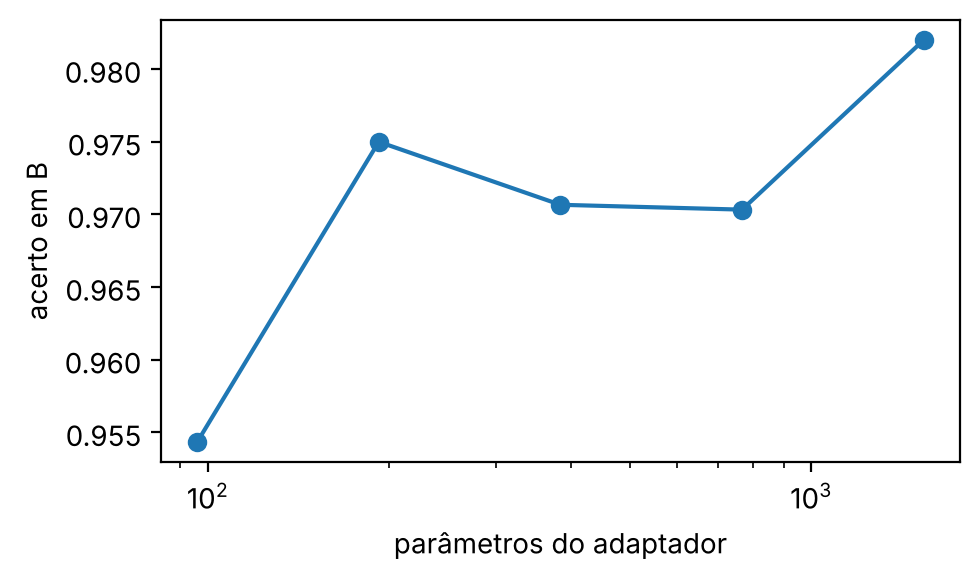

In [6]:
ranks = [1, 2, 4, 8, 16]
acc_r = [np.mean([rodar_B(40, "LoRA", rank=r, seed=s)[0] for s in range(5)]) for r in ranks]
par_r = [r * (32 + 64) for r in ranks]
for r, a, p in zip(ranks, acc_r, par_r):
    print(f"posto {r:2d}: {p:5d} parâmetros no adaptador, acerto {a:.1%}")
fig, ax = plt.subplots(figsize=(5, 3)); ax.plot(par_r, acc_r, "o-"); ax.set_xlabel("parâmetros do adaptador"); ax.set_ylabel("acerto em B"); ax.set_xscale("log"); plt.tight_layout()

Posto 1 já faz quase tudo, e o ganho **satura** a partir de 2 (as diferenças entre 2 e 16 estão dentro do ruído das sementes). Em modelos reais acontece o mesmo: postos de 8 a 64 costumam bastar, e aumentar o posto é um ajuste fino que se **mede**, não um botão que sempre ajuda.

## 6. O preço do ajuste completo: esquecimento

O ajuste muda os pesos, e o que o modelo sabia pode sumir. Depois de ajustar para a tarefa B, **a tarefa A** (qual máquina?) ainda funciona? Variamos a taxa de aprendizado, que controla o quanto os pesos se movem:

    lr | completo: B     A |  LoRA: B     A
 0.002 |         87%   67% |      96%  100%
 0.005 |         86%   62% |      96%   97%
 0.010 |         87%   57% |      96%   91%
 0.020 |         87%   50% |      96%   86%
 0.050 |         84%   36% |      98%   70%

LoRA (lr 0,02): tarefa A com o adaptador ligado 88%; com o adaptador DESLIGADO 100%  (modelo base original: 100%)


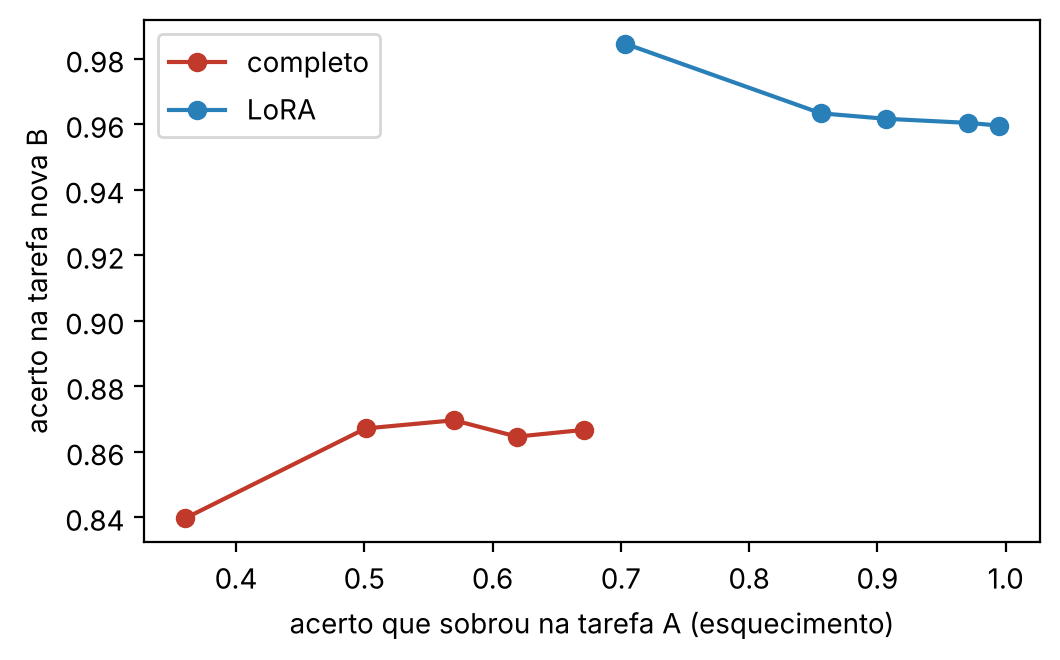

In [7]:
lrs = [0.002, 0.005, 0.01, 0.02, 0.05]
curva = {}
for metodo in ("completo", "LoRA"):
    curva[metodo] = [(np.mean([rodar_B(40, metodo, lr=lr, seed=s)[0] for s in range(4)]), np.mean([rodar_B(40, metodo, lr=lr, seed=s)[1] for s in range(4)])) for lr in lrs]
print(f"{'lr':>6s} | {'completo: B':>11s} {'A':>5s} | {'LoRA: B':>8s} {'A':>5s}")
for i, lr in enumerate(lrs):
    print(f"{lr:6.3f} | {curva['completo'][i][0]:11.0%} {curva['completo'][i][1]:5.0%} | {curva['LoRA'][i][0]:8.0%} {curva['LoRA'][i][1]:5.0%}")
fig, ax = plt.subplots(figsize=(5.4, 3.4))
for metodo, cor in (("completo", "#c0392b"), ("LoRA", "#2980b9")):
    ax.plot([a for _, a in curva[metodo]], [b for b, _ in curva[metodo]], "o-", color=cor, label=metodo)
ax.set_xlabel("acerto que sobrou na tarefa A (esquecimento)"); ax.set_ylabel("acerto na tarefa nova B"); ax.legend(); plt.tight_layout()
_, a_lora_on, net_l2, _ = rodar_B(40, "LoRA", lr=0.02)
net_l2.lora, tmp = None, net_l2.lora
print(f"\nLoRA (lr 0,02): tarefa A com o adaptador ligado {a_lora_on:.0%}; com o adaptador DESLIGADO {net_l2.accuracy(XteA, yteA, 'A'):.0%}  (modelo base original: {base.accuracy(XteA, yteA, 'A'):.0%})")

- No **ajuste completo**, a tarefa A cai de 100 % para ~67 % mesmo com a menor taxa, e para ~36 % com a maior: o modelo **esqueceu**. Para um modelo de linguagem, isso se manifesta como perder capacidades gerais (raciocínio, outros idiomas) ao ajustar para um domínio.
- No **LoRA** o esquecimento é menor e **controlável pela taxa**: B fica em ~96 a 98 % em todas as taxas, e A só cai muito (para ~70 %) com a taxa maior; com taxa pequena, A fica em 97 a 100 %. E o decisivo: **desligando o adaptador, o modelo volta a ser exatamente o base**, com 100 % em A. No ajuste completo não há como desfazer, só guardar uma cópia antes.

Então o ajuste exige **dois** números: o ganho na tarefa nova e o que se perdeu no resto. Um conjunto de **regressão** com as capacidades antigas é parte do ajuste, assim como o portão de qualidade do capítulo 5.

## 7. Quantos exemplos fazem falta

A pergunta que mais importa antes de começar. Curva de aprendizado: acerto em B contra número de exemplos, para cada método:

    n       do zero   só a cabeça      completo          LoRA
   10           60%           68%           58%           77%
   20           70%           80%           75%           90%
   40           81%           97%           87%           96%
   80           84%          100%           90%          100%
  160           86%          100%           93%          100%
  320           85%          100%           93%          100%


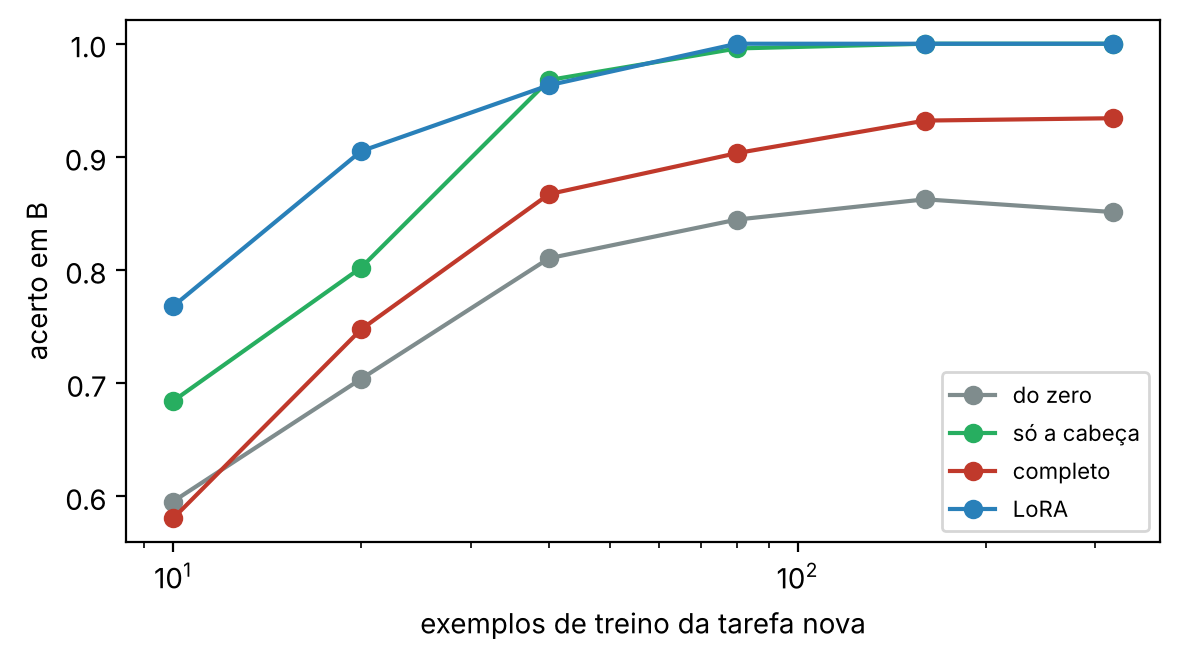

In [8]:
ns = [10, 20, 40, 80, 160, 320]
curvas = {m: [np.mean([rodar_B(n, m, seed=s)[0] for s in range(4)]) for n in ns] for m in metodos}
fig, ax = plt.subplots(figsize=(6, 3.4))
for m, cor in zip(metodos, ["#7f8c8d", "#27ae60", "#c0392b", "#2980b9"]):
    ax.plot(ns, curvas[m], "o-", label=m, color=cor)
ax.set_xscale("log"); ax.set_xlabel("exemplos de treino da tarefa nova"); ax.set_ylabel("acerto em B"); ax.legend(fontsize=8); plt.tight_layout()
print(f"{'n':>5s} " + " ".join(f"{m:>13s}" for m in metodos))
for i, n in enumerate(ns):
    print(f"{n:5d} " + " ".join(f"{curvas[m][i]:13.0%}" for m in metodos))

- Com **10 a 20 exemplos**, LoRA e a cabeça já passam bastante do treino do zero.
- A partir de **80 exemplos**, LoRA e cabeça chegam perto de 100 %, e **o ajuste completo e o treino do zero estacionam** (~93 % e ~85 %): como os exemplos nunca mostram os sinônimos escondidos, nenhum número de exemplos **iguais em cobertura** conserta isso.

A lição vale para qualquer ajuste: **a cobertura dos dados importa mais que a quantidade**. Mil exemplos que só mostram metade das situações não ensinam a outra metade. Como montar, limpar e ampliar esses dados é o assunto do capítulo 8.

## 8. Quantização, e QLoRA em miniatura

Quantizar é guardar cada peso com menos bits. A versão mais simples, **simétrica por maior valor absoluto**: escolhe-se uma **escala** `s = max|W| / (2^(b-1) - 1)` e cada peso vira o inteiro mais próximo de `W/s`. A conta de volta (`inteiro × s`) devolve um valor **aproximado**. A escala pode ser **uma para o tensor todo** ou **uma por grupo** de valores vizinhos.

Efeito nos pesos do modelo base (vetores `E` e matriz `W`) na tarefa A:

In [9]:
def base_quantizada(bits, grupo=None, outlier=False):
    q = copy.deepcopy(base)
    W = q.p["W"].copy()
    if outlier:
        W[0, 0] = 25 * np.abs(W).max()          # um peso fora de escala, como existem em modelos reais
    q.p["W"] = quantize(W, bits, grupo); q.p["E"] = quantize(q.p["E"], bits, grupo)
    return q
print(f"{'bits':>5s} {'tensor inteiro':>15s} {'por grupo de 16':>16s} | {'com 1 outlier: tensor':>22s} {'grupo':>7s}")
for bits in (8, 6, 4, 3, 2):
    a = lambda **k: base_quantizada(bits, **k).accuracy(XteA, yteA, "A")
    print(f"{bits:5d} {a():15.0%} {a(grupo=16):16.0%} | {a(outlier=True):22.0%} {a(grupo=16, outlier=True):7.0%}")
print(f"\nreferência (32 bits): {base.accuracy(XteA, yteA, 'A'):.0%}")

 bits  tensor inteiro  por grupo de 16 |  com 1 outlier: tensor   grupo
    8            100%             100% |                   100%    100%
    6            100%             100% |                   100%    100%
    4            100%             100% |                     8%    100%
    3            100%             100% |                     8%    100%
    2             98%             100% |                     8%    100%

referência (32 bits): 100%


- **Sem outlier**, esta rede pequena quase não sente a quantização: mesmo com 2 bits o acerto fica em 98 a 100 %. Não generalize: a tarefa é fácil e a rede é redundante, e modelos de linguagem reais sentem a perda a partir de 4 ou 3 bits.
- Com **um único peso fora de escala** (outlier), a escala do tensor inteiro **é puxada por ele** e todos os outros pesos são arredondados para quase zero: o acerto desaba. Com escala **por grupo**, o estrago fica confinado ao grupo do outlier. Modelos de linguagem reais têm outliers, e por isso os métodos de 4 bits usam **grupos** (e alguns tratam os outliers à parte).
- Note também que com 8 e 6 bits o outlier não faz mal (há níveis de sobra), e com 4 bits ou menos o tensor inteiro cai para 8 %. Quantização é uma troca de **memória por qualidade**, e o único jeito honesto de escolher é **medir no seu conjunto de avaliação**.

### QLoRA em miniatura

O QLoRA junta as duas ideias: **quantiza o modelo base (congelado) em 4 bits** e **treina o LoRA por cima**, em precisão normal. A memória cai por causa do base quantizado, e o adaptador conserta parte do erro de quantização. Em miniatura:

In [10]:
base4 = base_quantizada(4, grupo=16)
r_normal = [rodar_B(40, "LoRA", seed=s)[0] for s in range(5)]
r_q = [rodar_B(40, "LoRA", seed=s, rede=base4)[0] for s in range(5)]
print(f"LoRA sobre o base em precisão cheia: {np.mean(r_normal):.1%}")
print(f"LoRA sobre o base em 4 bits (QLoRA): {np.mean(r_q):.1%}")
print(f"memória dos pesos congelados: 32 bits -> 4 bits = {32 / 4:.0f} vezes menor")

LoRA sobre o base em precisão cheia: 97.1%
LoRA sobre o base em 4 bits (QLoRA): 97.4%
memória dos pesos congelados: 32 bits -> 4 bits = 8 vezes menor


O QLoRA fica **muito perto** do LoRA completo, com os pesos congelados ocupando uma fração da memória. É o que permite ajustar um modelo de 70 B numa única GPU grande, como a tabela da seção 2 mostrou. A conta é a mesma; o modelo é que é maior.

## Erros comuns

- **Ajustar para ensinar fatos.** Use RAG; o ajuste ensina comportamento.
- **Ajustar antes de tentar prompt e RAG**, e sem conjunto de avaliação.
- **Medir só o ganho na tarefa nova.** Meça também o que o modelo esqueceu.
- **Dados que cobrem só uma parte das situações.** Cobertura importa mais que volume.
- **Esquecer o custo de memória** do otimizador e das ativações na hora de escolher a GPU.
- **Quantizar sem medir.** Um outlier ou 3 bits podem derrubar a qualidade.
- **Achar que mais posto é sempre melhor.** Meça: costuma saturar cedo.
- **Perder o modelo base** depois de um ajuste completo. Com LoRA o adaptador é separado.

## Confira o que ficou

**1. Quando usar RAG e quando finetuning?**

<details><summary>Ver resposta</summary>

RAG para conhecimento (fatos que mudam e precisam de fonte); finetuning para comportamento (formato, jargão, tarefa estreita e repetida).

</details>

**2. Por que o ajuste completo de um modelo de 7 B pede mais de 100 GB, se rodá-lo pede uns 14 GB?**

<details><summary>Ver resposta</summary>

Porque guarda também os gradientes e os estados do otimizador (cerca de 16 bytes por parâmetro no total), além das ativações.

</details>

**3. O que o LoRA treina, e por que a memória cai?**

<details><summary>Ver resposta</summary>

Duas matrizes finas por peso (desvio de posto baixo). Os gradientes e os estados do otimizador existem só para elas, que são uma fração pequena dos parâmetros.

</details>

**4. Por que 'desligar o adaptador' é uma vantagem do LoRA?**

<details><summary>Ver resposta</summary>

O modelo base fica intacto: dá para voltar a ele, trocar de adaptador ou servir vários adaptadores sobre o mesmo modelo.

</details>

**5. Por que um único peso fora de escala estraga a quantização por tensor inteiro?**

<details><summary>Ver resposta</summary>

A escala vem do maior valor absoluto: o outlier a infla e os demais pesos viram quase zero ao arredondar. Por grupo, o estrago fica no grupo dele.

</details>

**6. O ajuste completo foi pior que o LoRA aqui. Por quê?**

<details><summary>Ver resposta</summary>

Com poucos exemplos mostrando só parte dos sinônimos, ele desloca os vetores das palavras vistas e desfaz a estrutura que ligava as não vistas; o LoRA preserva os vetores.

</details>

**7. O que é o QLoRA?**

<details><summary>Ver resposta</summary>

LoRA treinado sobre um modelo base quantizado em 4 bits e congelado: reduz a memória dos pesos congelados mantendo o adaptador em precisão normal.

</details>

## Exercícios

1. **Cobertura:** mude `treino_seen` de 2 para 3 sinônimos e depois para 4. O que acontece com o ajuste completo?
2. **Rank e alvo:** aplique o LoRA também aos vetores `E` (uma matriz de desvio de posto baixo). Ajuda ou atrapalha?
3. **Memória real:** recalcule a tabela da seção 2 para um modelo de 3 B e rank 8. Ele cabe numa GPU de 24 GB para ajuste completo? E em LoRA?
4. **Bits:** a rede aguenta até 2 bits sem outlier. Torne a tarefa mais difícil (mais classes, ruído nas anotações) e veja onde o acerto começa a cair. A posição muda com o tamanho do grupo (8, 32, 64)?
5. **Esquecimento mensurável:** crie um conjunto de regressão da tarefa A e um portão que bloqueie um ajuste que derrube A mais de 5 pontos.
6. **Fusão de adaptadores:** treine dois adaptadores (tarefas diferentes) e some os dois desvios em `W`. Os dois comportamentos sobrevivem?
7. **Taxa de aprendizado:** por que a taxa do LoRA pode ser maior que a do ajuste completo sem estragar A tanto?

## Glossário

- **Finetuning (ajuste):** continuar o treino de um modelo com dados da sua tarefa.
- **Ajuste completo:** atualizar todos os parâmetros.
- **LoRA:** aprender um desvio de posto baixo para cada matriz escolhida, mantendo os pesos originais congelados.
- **Posto (rank):** a "largura" do desvio; limita quantas direções ele pode mudar.
- **Adaptador:** o conjunto de matrizes do LoRA, pequeno e trocável.
- **Estados do otimizador:** números extras por parâmetro (no Adam, dois) guardados durante o treino.
- **Quantização:** guardar pesos com menos bits.
- **Outlier:** valor muito maior que os demais, que desorganiza a escala da quantização.
- **QLoRA:** LoRA sobre um modelo base quantizado em 4 bits.
- **Esquecimento:** perda de capacidades antigas depois de ajustar para uma nova.
- **Sondagem linear:** treinar só a camada de saída sobre representações congeladas.

## Próximo passo

**Notebook 08, capítulo 8 (Dataset Engineering):** como montar os dados que alimentam um ajuste ou uma avaliação: cobertura, deduplicação, limpeza, dados sintéticos e anotação, com relatos de parada como material.